## Visualização e pré-processamento

*Kalil Nege — RA 2409020 · OPT098 - Tópicos Especiais em Sistemas de Computação (Prof. Dr. Rodrigo Hübner)*

O BETA já vem filtrado pelos autores (3–100 Hz), então aqui o trabalho é mais **olhar o sinal** e definir os recortes:

1. conferir se ainda há ruído de rede em 50 Hz;
2. definir a janela **com estímulo** e a janela **sem estímulo**;
3. filtrar, montar o `mne.EpochsArray` e salvar.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
from scipy import signal
from glob import glob
import os
import mne

mne.set_log_level('WARNING')
rcParams['figure.figsize'] = [14., 4.]

fs = 250
CANAIS_SSVEP = ['PZ', 'PO5', 'PO3', 'POZ', 'PO4', 'PO6', 'O1', 'OZ', 'O2']
OZ = CANAIS_SSVEP.index('OZ')

arquivos = sorted(glob('dados/npz/S*.npz'), key=lambda a: int(a.split('S')[-1][:-4]))
SUJEITOS = [int(a.split('S')[-1][:-4]) for a in arquivos]
print(len(SUJEITOS), 'participantes')


def passa_faixa(sinal, corte_inf, corte_sup, fs=250, ordem=4):
    nyq = fs * 0.5
    b, a = signal.butter(ordem, [corte_inf / nyq, corte_sup / nyq], btype='bandpass')
    return signal.filtfilt(b, a, sinal, axis=-1)

70 participantes


### Ruído de rede

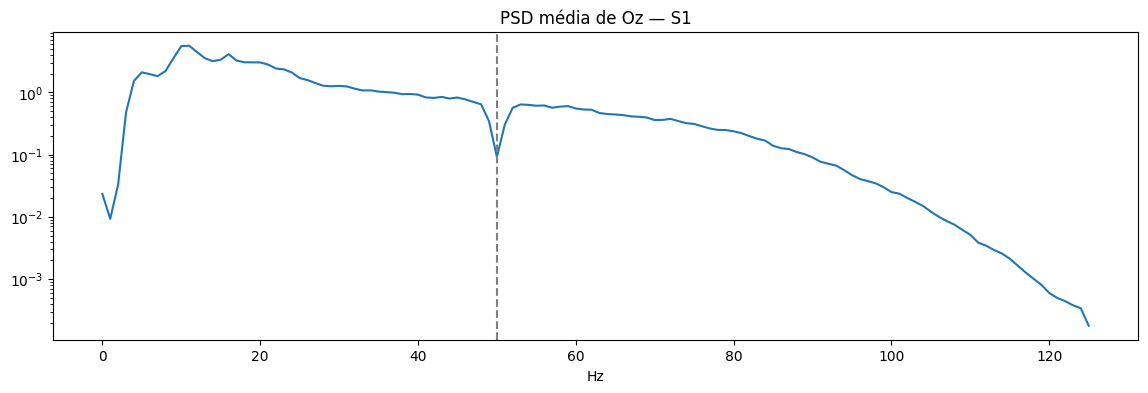

In [2]:
d = np.load(arquivos[0])
X, freqs = d['X'], d['freqs']
f, P = signal.welch(X[:, :, OZ, :], fs=fs, nperseg=fs, axis=-1)

plt.semilogy(f, P.mean(axis=(0, 1)))
plt.axvline(50, ls='--', c='gray')
plt.xlabel('Hz'); plt.title(f'PSD média de Oz — S{SUJEITOS[0]}')
plt.show()

Em 50 Hz não há pico, e sim um "vale": o filtro rejeita-faixa do amplificador já resolveu, então não aplico outro. Também não há nada abaixo de 3 Hz, por causa do filtro dos autores.

### Janelas de análise

- **com estímulo**: o estímulo começa em 0,5 s, mas a resposta visual demora cerca de **130 ms** para aparecer (valor estimado no artigo do BETA, que também o soma antes de classificar). Uso então de 0,63 s a 2,63 s, ou seja, **2 s**, o máximo que cabe nos ensaios de S1–S15 (3 s no total);
- **sem estímulo**: os 0,5 s antes do início do estímulo. Os 0,5 s do final não entram, porque o artigo avisa que ali ainda pode haver SSVEP.

Nos canais de SSVEP aplico o passa-faixa de **6 a 80 Hz**, o mesmo do artigo, no ensaio inteiro antes de recortar. Nos canais de ritmo mantenho o sinal como veio, porque preciso de teta (4–8 Hz).

In [3]:
ini = int(0.5 * fs) + round(0.13 * fs)
fim = ini + 2 * fs
pre = int(0.5 * fs)
print(f'com estímulo: amostras {ini}–{fim} | sem estímulo: amostras 0–{pre}')

com estímulo: amostras 157–657 | sem estímulo: amostras 0–125


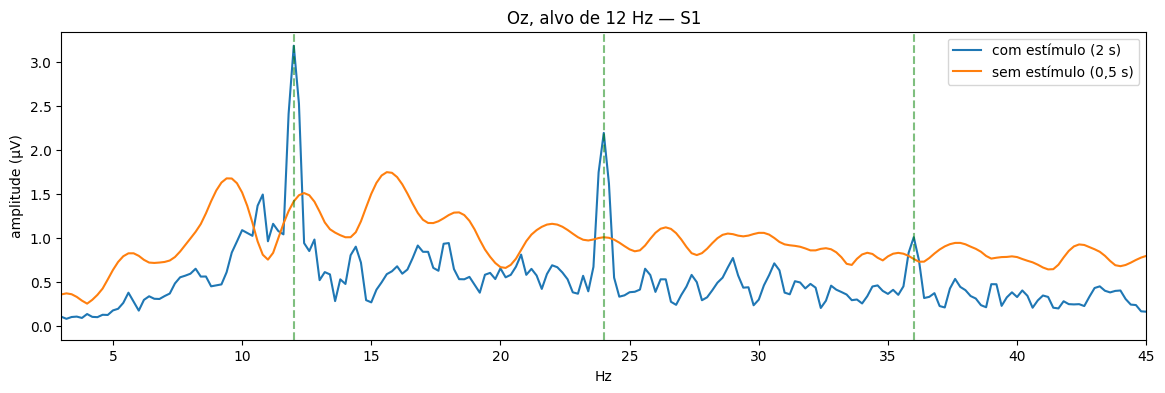

In [4]:
oz = passa_faixa(X[..., :fim + fs // 2], 6., 80.)[:, :, OZ]
c = list(freqs).index(12.0)

nfft = 5 * fs
fr = np.fft.rfftfreq(nfft, 1 / fs)
for trecho, nome in ((oz[:, c, ini:fim], 'com estímulo (2 s)'), (oz[:, c, :pre], 'sem estímulo (0,5 s)')):
    amp = np.abs(np.fft.rfft(trecho, n=nfft, axis=-1)).mean(axis=0) / trecho.shape[-1]
    plt.plot(fr, amp, label=nome)
for h in (1, 2, 3):
    plt.axvline(12 * h, ls='--', c='green', alpha=.5)
plt.xlim(3, 45); plt.xlabel('Hz'); plt.ylabel('amplitude (µV)')
plt.title(f'Oz, alvo de 12 Hz — S{SUJEITOS[0]}'); plt.legend(); plt.show()

Com estímulo aparecem os picos em 12, 24 e 36 Hz; sem estímulo, não. A janela de 0,5 s tem resolução de só 2 Hz, por isso a curva é tão suave.

### Objeto `mne.EpochsArray`

<EpochsArray | 160 events (all good), 0 – 1.996 s (baseline off), ~5.5 MiB, data loaded,
 '8.0': 4
 '8.2': 4
 '8.4': 4
 '8.6': 4
 '8.8': 4
 '9.0': 4
 '9.2': 4
 '9.4': 4
 '9.6': 4
 '9.8': 4
 and 30 more events ...>


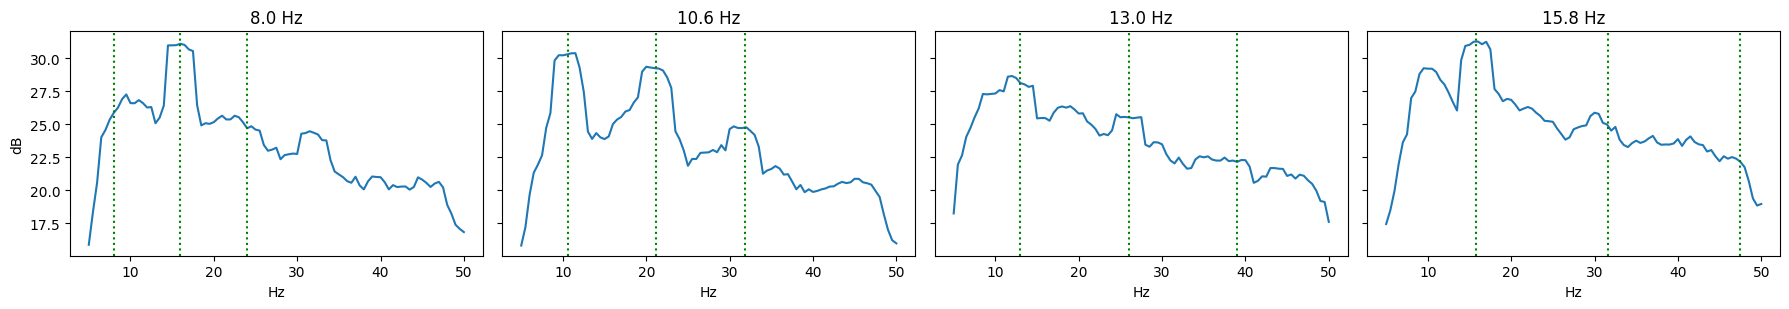

In [5]:
def para_mne(janelas, freqs, canais):
    n_blocos, n_alvos = janelas.shape[:2]
    ep = janelas.reshape(n_blocos * n_alvos, len(canais), -1)
    codigos = np.tile(np.arange(n_alvos), n_blocos)
    eventos = np.column_stack((np.arange(len(ep)), np.zeros(len(ep), int), codigos))
    info = mne.create_info(canais, fs, 'eeg')
    return mne.EpochsArray(ep, info, eventos, event_id={f'{f:.1f}': i for i, f in enumerate(freqs)})


ssvep = passa_faixa(X[:, :, :9, :fim + fs // 2], 6., 80.)[..., ini:fim]
epocas = para_mne(ssvep, freqs, CANAIS_SSVEP)
print(epocas)

fig, eixos = plt.subplots(1, 4, figsize=(18, 3.2), sharey=True)
for eixo, f0 in zip(eixos, (8.0, 10.6, 13.0, 15.8)):
    psd = epocas[f'{f0:.1f}'].compute_psd(method='multitaper', fmin=5, fmax=50)
    eixo.plot(psd.freqs, 10 * np.log10(psd.get_data().mean(axis=(0, 1))))
    for h in (1, 2, 3):
        eixo.axvline(f0 * h, ls=':', c='green')
    eixo.set_title(f'{f0} Hz'); eixo.set_xlabel('Hz')
eixos[0].set_ylabel('dB')
plt.tight_layout(); plt.show()

### Salvamento

Para cada participante salvo os canais occipitais filtrados (`ssvep`) e os canais frontais/centrais com e sem estímulo (`ritmo` e `ritmo_pre`).

In [6]:
os.makedirs('dados/epocas', exist_ok=True)
for s, arq in zip(SUJEITOS, arquivos):
    X = np.load(arq)['X'][..., :fim + fs // 2]
    occ = passa_faixa(X[:, :, :9], 6., 80.).astype(np.float32)
    np.savez(f'dados/epocas/S{s}.npz', ssvep=occ[..., ini:fim],
             ritmo=X[:, :, 9:, ini:fim], ritmo_pre=X[:, :, 9:, :pre])
print('com estímulo:', occ[..., ini:fim].shape, '| sem estímulo:', X[:, :, 9:, :pre].shape)

com estímulo: (4, 40, 9, 500) | sem estímulo: (4, 40, 9, 125)
